In [1]:
import sys

print(sys.executable)

c:\Users\Pichau\Downloads\projeto novembro\projeto_viagens\.venv\Scripts\python.exe


In [2]:
from banco import conectar

conexao = conectar()

try:
    with conexao.cursor() as cursor:
        cursor.execute("SELECT current_database();")
        banco = cursor.fetchone()[0]

    print("Notebook conectado ao banco:", banco)
finally:
    conexao.close()

Notebook conectado ao banco: projeto_viagens


In [3]:
import pandas as pd
import matplotlib.pyplot as plt


def consultar(sql):
    conexao = conectar()

    try:
        with conexao.cursor() as cursor:
            cursor.execute(sql)
            linhas = cursor.fetchall()
            colunas = [coluna[0] for coluna in cursor.description]

        return pd.DataFrame(linhas, columns=colunas)
    finally:
        conexao.close()


consultar("""
    SELECT COUNT(*) AS total_viagens
    FROM silver_viagem
""")

,total_viagens
0,341860


,cod_orgao_superior,orgao,quantidade_viagens,custo_total
0,30000,Ministério da Justiça e Segurança Pública,75742,486933121.65
1,52000,Ministério da Defesa,61912,156070304.49
2,26000,Ministério da Educação,65295,111291349.34
3,44000,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16
4,33000,Ministério da Previdência Social,8190,40417309.06


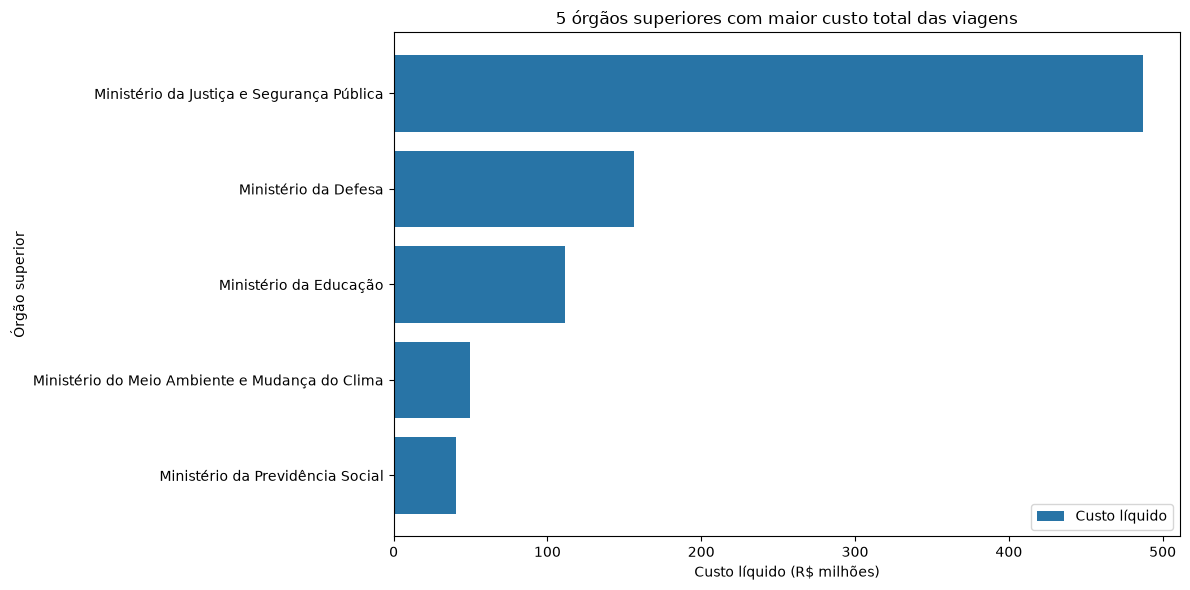

In [4]:
orgaos = consultar("""
    SELECT
        cod_orgao_superior,
        nome_orgao_superior AS orgao,
        COUNT(*) AS quantidade_viagens,
        SUM(valor_total) AS custo_total
    FROM silver_viagem
    GROUP BY cod_orgao_superior, nome_orgao_superior
    ORDER BY custo_total DESC, cod_orgao_superior
    LIMIT 5
""")

display(orgaos)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    orgaos["orgao"],
    orgaos["custo_total"].astype(float) / 1_000_000,
    color="#2874A6",
    label="Custo líquido",
)

ax.invert_yaxis()
ax.set_title("5 órgãos superiores com maior custo total das viagens")
ax.set_xlabel("Custo líquido (R$ milhões)")
ax.set_ylabel("Órgão superior")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 1 — Órgãos com maior custo total

O Ministério da Justiça e Segurança Pública apresentou o maior
custo líquido de viagens na base analisada: R$ 486,93 milhões,
distribuídos em 75.742 viagens.

Na sequência aparecem os ministérios da Defesa (R$ 156,07 milhões),
da Educação (R$ 111,29 milhões), do Meio Ambiente e Mudança do
Clima (R$ 49,70 milhões) e da Previdência Social (R$ 40,42 milhões).

O custo líquido corresponde à soma de diárias, passagens e outros
gastos, descontadas as devoluções. O agrupamento considera o órgão
superior.

O maior gasto total, isoladamente, não permite concluir que há
ineficiência: também é necessário considerar o volume, a duração
e as características das viagens.

,cidade,uf,quantidade_viagens,custo_medio
0,Tejupá,São Paulo,1,115175.000000000000
1,Chavantes,São Paulo,1,114557.010000000000
2,Teolândia,Bahia,1,109322.500000000000


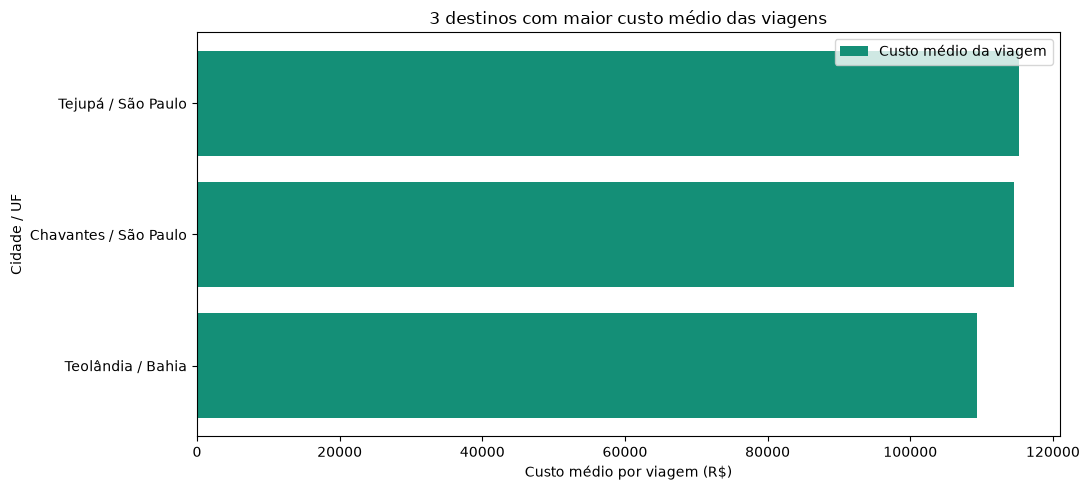

In [5]:
destinos = consultar("""
    WITH destinos_por_viagem AS (
        SELECT DISTINCT
            id_viagem,
            destino_cidade,
            destino_uf
        FROM silver_trecho
        WHERE NULLIF(TRIM(destino_cidade), '') IS NOT NULL
    )
    SELECT
        t.destino_cidade AS cidade,
        t.destino_uf AS uf,
        COUNT(*) AS quantidade_viagens,
        AVG(v.valor_total) AS custo_medio
    FROM destinos_por_viagem AS t
    JOIN silver_viagem AS v
        ON v.id_viagem = t.id_viagem
    GROUP BY t.destino_cidade, t.destino_uf
    ORDER BY custo_medio DESC, cidade, uf
    LIMIT 3
""")

display(destinos)

rotulos = (
    destinos["cidade"]
    + " / "
    + destinos["uf"].fillna("").replace("", "Não informada")
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    rotulos,
    destinos["custo_medio"].astype(float),
    color="#148F77",
    label="Custo médio da viagem",
)

ax.invert_yaxis()
ax.set_title("3 destinos com maior custo médio das viagens")
ax.set_xlabel("Custo médio por viagem (R$)")
ax.set_ylabel("Cidade / UF")
ax.ticklabel_format(style="plain", axis="x")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 2 — Destinos com maior custo médio por viagem

Os maiores custos médios foram observados em:

- Tejupá / São Paulo: R$ 115.175,00.
- Chavantes / São Paulo: R$ 114.557,01.
- Teolândia / Bahia: R$ 109.322,50.

Cada destino aparece em apenas uma viagem na base analisada.
Portanto, essas médias refletem casos individuais e não permitem
concluir que esses destinos sejam habitualmente mais caros.

A consulta considera cada viagem uma única vez por cidade e UF
visitadas. O valor utilizado é o custo líquido completo da viagem,
sem divisão entre seus destinos. Por isso, os valores de diferentes
destinos não devem ser somados como gastos exclusivos de cada cidade.

,id_viagem,orgao,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,383,0.00


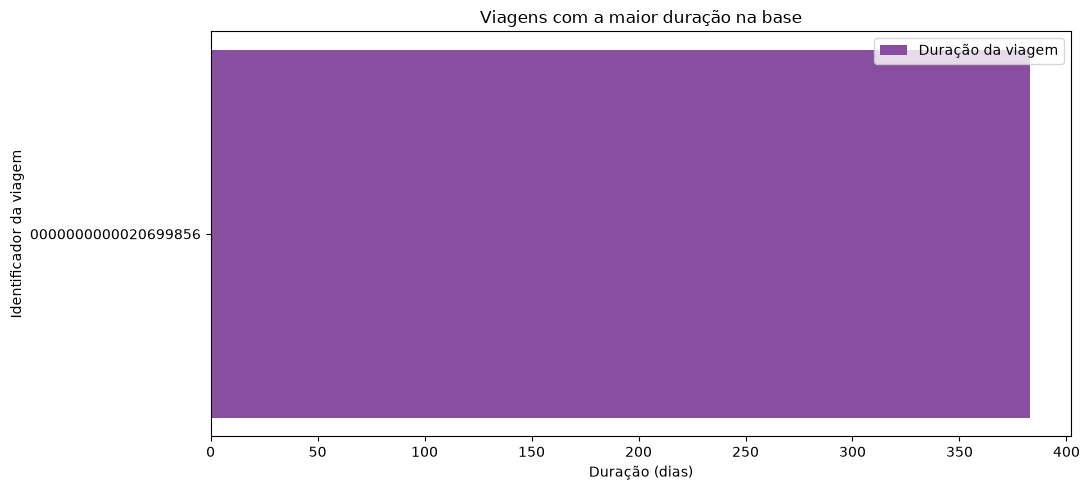

In [6]:
maior_duracao = consultar("""
    SELECT
        id_viagem,
        nome_orgao_superior AS orgao,
        data_inicio,
        data_fim,
        duracao_dias,
        valor_total
    FROM silver_viagem
    WHERE duracao_dias = (
        SELECT MAX(duracao_dias)
        FROM silver_viagem
    )
    ORDER BY id_viagem
""")

display(maior_duracao)

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    maior_duracao["id_viagem"],
    maior_duracao["duracao_dias"],
    color="#884EA0",
    label="Duração da viagem",
)

ax.invert_yaxis()
ax.set_title("Viagens com a maior duração na base")
ax.set_xlabel("Duração (dias)")
ax.set_ylabel("Identificador da viagem")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 3 — Viagem de maior duração

A viagem de maior duração pertence ao Ministério da Previdência
Social, com início em 13/01/2025 e término em 31/01/2026.

A duração calculada pela diferença entre as datas é de 383 dias,
e o custo líquido registrado na base é de R$ 0,00.

O término em 2026 foi preservado, pois a viagem começou no primeiro
semestre de 2025. Não foi aplicado um corte artificial na data final.

A combinação de duração elevada e custo registrado igual a zero
merece investigação nos dados de origem. Esse resultado, isoladamente,
não comprova erro nem ausência de despesas fora da base analisada.

In [7]:
conexao = conectar()

try:
    with conexao:
        with conexao.cursor() as cursor:
            cursor.execute("""
                CREATE OR REPLACE VIEW vw_gold_pagamentos AS
                SELECT
                    p.nome_orgao_pagador,
                    p.tipo_pagamento,
                    COUNT(*) AS quantidade_pagamentos,
                    COUNT(p.valor) AS quantidade_com_valor,
                    SUM(p.valor) AS valor_total
                FROM silver_pagamento AS p
                JOIN silver_viagem AS v
                    ON v.id_viagem = p.id_viagem
                GROUP BY
                    p.nome_orgao_pagador,
                    p.tipo_pagamento
            """)

            cursor.execute("""
                CREATE TABLE IF NOT EXISTS gold_pagamentos AS
                SELECT *
                FROM vw_gold_pagamentos
                WITH NO DATA
            """)

            cursor.execute("TRUNCATE TABLE gold_pagamentos")

            cursor.execute("""
                INSERT INTO gold_pagamentos (
                    nome_orgao_pagador,
                    tipo_pagamento,
                    quantidade_pagamentos,
                    quantidade_com_valor,
                    valor_total
                )
                SELECT
                    nome_orgao_pagador,
                    tipo_pagamento,
                    quantidade_pagamentos,
                    quantidade_com_valor,
                    valor_total
                FROM vw_gold_pagamentos
            """)

    print("VIEW e tabela Gold de pagamentos criadas e atualizadas!")

finally:
    conexao.close()

VIEW e tabela Gold de pagamentos criadas e atualizadas!


,tipo_pagamento,quantidade,valor_medio
0,PASSAGEM,186008,1856.7780791148767795
1,DIÁRIAS,366351,1797.5529279297722676
2,Serviço correlato: seguro,4882,447.7247685374846374
3,RESTITUIÇÃO,11570,245.6939343128781331


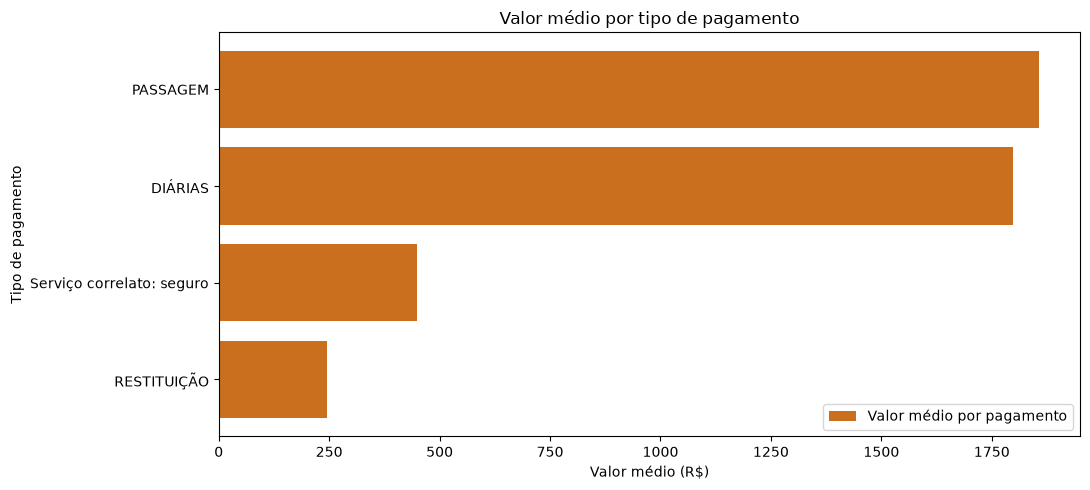

In [8]:
tipos_pagamento = consultar("""
    SELECT
        tipo_pagamento,
        SUM(quantidade_pagamentos) AS quantidade,
        SUM(valor_total)
            / NULLIF(SUM(quantidade_com_valor), 0) AS valor_medio
    FROM gold_pagamentos
    GROUP BY tipo_pagamento
    HAVING SUM(quantidade_com_valor) > 0
    ORDER BY valor_medio DESC, tipo_pagamento
""")

display(tipos_pagamento)

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    tipos_pagamento["tipo_pagamento"],
    tipos_pagamento["valor_medio"].astype(float),
    color="#CA6F1E",
    label="Valor médio por pagamento",
)

ax.invert_yaxis()
ax.set_title("Valor médio por tipo de pagamento")
ax.set_xlabel("Valor médio (R$)")
ax.set_ylabel("Tipo de pagamento")
ax.ticklabel_format(style="plain", axis="x")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 4 — Tipo de pagamento com maior valor médio

O tipo PASSAGEM apresentou o maior valor médio por pagamento:
R$ 1.856,78, considerando 186.008 registros.

DIÁRIAS ficou em segundo lugar, com média de R$ 1.797,55,
mas apresentou a maior quantidade de pagamentos: 366.351.

Os demais valores médios foram R$ 447,72 para serviço correlato:
seguro e R$ 245,69 para restituição.

As médias foram calculadas a partir da Gold, dividindo a soma dos
valores pela quantidade de pagamentos com valor informado.
A unidade de análise é cada registro de pagamento, não cada viagem.

In [9]:
conexao = conectar()

try:
    with conexao:
        with conexao.cursor() as cursor:
            cursor.execute("""
                CREATE OR REPLACE VIEW vw_gold_trechos AS
                SELECT
                    t.meio_transporte,
                    t.destino_uf,
                    COUNT(*) AS quantidade_trechos
                FROM silver_trecho AS t
                JOIN silver_viagem AS v
                    ON v.id_viagem = t.id_viagem
                GROUP BY
                    t.meio_transporte,
                    t.destino_uf
            """)

            cursor.execute("""
                CREATE TABLE IF NOT EXISTS gold_trechos AS
                SELECT *
                FROM vw_gold_trechos
                WITH NO DATA
            """)

            cursor.execute("TRUNCATE TABLE gold_trechos")

            cursor.execute("""
                INSERT INTO gold_trechos (
                    meio_transporte,
                    destino_uf,
                    quantidade_trechos
                )
                SELECT
                    meio_transporte,
                    destino_uf,
                    quantidade_trechos
                FROM vw_gold_trechos
            """)

            cursor.execute("""
                SELECT SUM(quantidade_trechos)
                FROM gold_trechos
            """)
            total_gold = cursor.fetchone()[0]

            cursor.execute("SELECT COUNT(*) FROM silver_trecho")
            total_silver = cursor.fetchone()[0]

            if total_gold != total_silver:
                raise RuntimeError("Contagem da Gold divergente.")

    print("VIEW e tabela Gold de trechos criadas e atualizadas!")
    print("Total de trechos representados:", total_gold)

finally:
    conexao.close()
    

VIEW e tabela Gold de trechos criadas e atualizadas!
Total de trechos representados: 763349


,transporte,quantidade_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


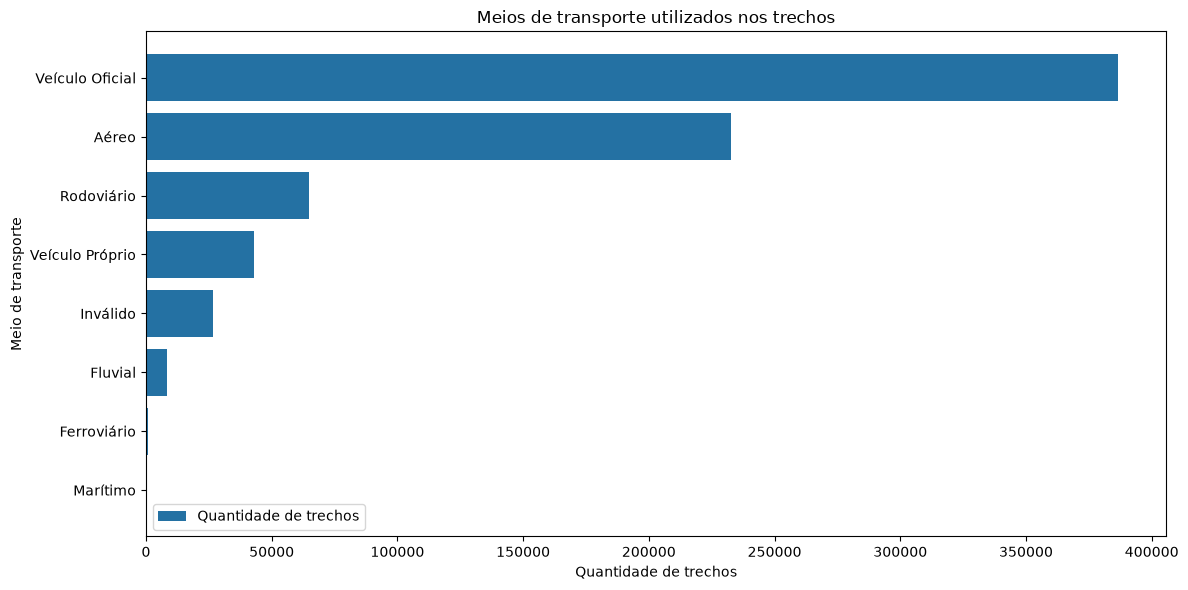

In [10]:
transportes = consultar("""
    SELECT
        COALESCE(
            NULLIF(TRIM(meio_transporte), ''),
            'Não informado'
        ) AS transporte,
        SUM(quantidade_trechos) AS quantidade_trechos
    FROM gold_trechos
    GROUP BY 1
    ORDER BY quantidade_trechos DESC, transporte
""")

display(transportes)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    transportes["transporte"],
    transportes["quantidade_trechos"].astype(int),
    color="#2471A3",
    label="Quantidade de trechos",
)

ax.invert_yaxis()
ax.set_title("Meios de transporte utilizados nos trechos")
ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("Meio de transporte")
ax.ticklabel_format(style="plain", axis="x")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 5 — Meio de transporte mais utilizado

Veículo Oficial foi a categoria mais frequente, com 386.424
trechos, seguida pelo transporte Aéreo, com 232.666 trechos.

A contagem considera trechos, e uma mesma viagem pode conter
vários deslocamentos.

Foram encontrados 26.659 trechos classificados como "Inválido"
na origem. Essa categoria foi mantida visível para evidenciar
a limitação de qualidade dos dados, sem presumir qual transporte
foi utilizado.

In [11]:
ufs = consultar("""
    SELECT
        destino_uf AS uf,
        SUM(quantidade_trechos) AS quantidade_trechos
    FROM gold_trechos
    WHERE destino_uf IN (
        'AC', 'AL', 'AP', 'AM', 'BA', 'CE', 'DF',
        'ES', 'GO', 'MA', 'MT', 'MS', 'MG', 'PA',
        'PB', 'PR', 'PE', 'PI', 'RJ', 'RN', 'RS',
        'RO', 'RR', 'SC', 'SP', 'SE', 'TO',
        'Acre', 'Alagoas', 'Amapá', 'Amazonas',
        'Bahia', 'Ceará', 'Distrito Federal',
        'Espírito Santo', 'Goiás', 'Maranhão',
        'Mato Grosso', 'Mato Grosso do Sul',
        'Minas Gerais', 'Pará', 'Paraíba', 'Paraná',
        'Pernambuco', 'Piauí', 'Rio de Janeiro',
        'Rio Grande do Norte', 'Rio Grande do Sul',
        'Rondônia', 'Roraima', 'Santa Catarina',
        'São Paulo', 'Sergipe', 'Tocantins'
    )
    GROUP BY destino_uf
    ORDER BY quantidade_trechos DESC, uf
""")

display(ufs)

,uf,quantidade_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


### Análise 6 — UF de destino mais frequente

São Paulo foi a UF com mais trechos de destino na base analisada,
com 82.722 registros. Em seguida aparecem o Distrito Federal,
com 79.962, e Minas Gerais, com 50.965.

A contagem representa trechos, não viagens distintas nem viajantes.
Foram consideradas apenas as 27 UFs brasileiras, incluindo o
Distrito Federal, excluindo valores vazios e outras classificações.


,orgao,quantidade_pagamentos,total_pago
0,Sigiloso,86878,170659883.35
1,Fundo Nacional de Segurança Pública,53440,141911719.64
2,Comando da Aeronáutica,45962,81180823.06
3,Comando do Exército,22056,35901379.45
4,Instituto Nacional do Seguro Social,17899,35385354.57


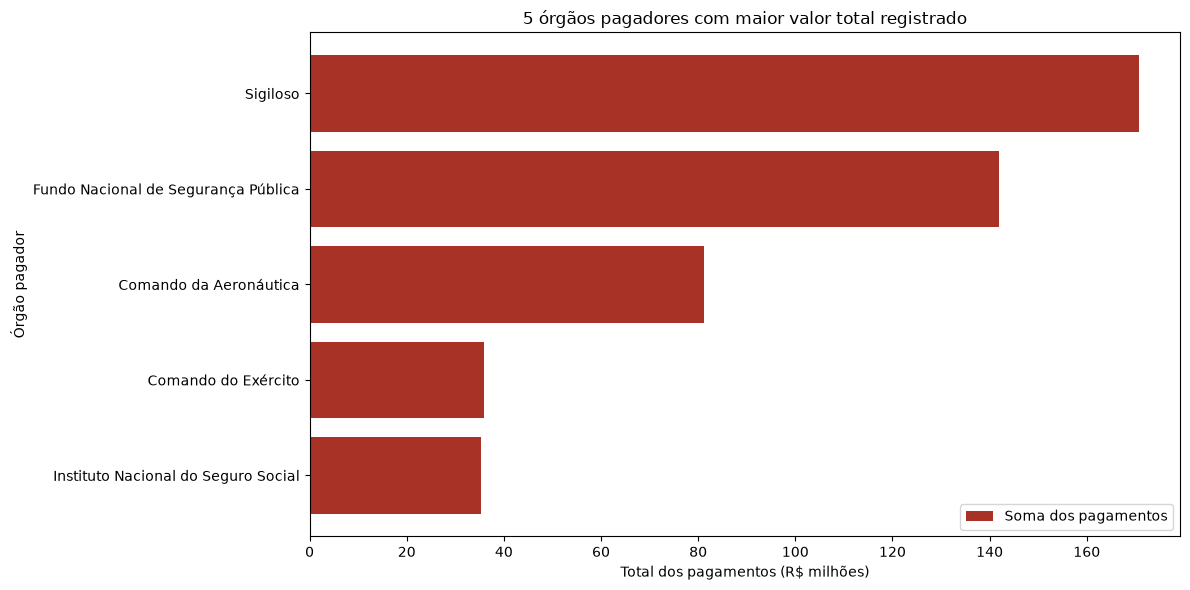

In [12]:
orgaos_pagadores = consultar("""
    SELECT
        nome_orgao_pagador AS orgao,
        SUM(quantidade_pagamentos) AS quantidade_pagamentos,
        SUM(valor_total) AS total_pago
    FROM gold_pagamentos
    WHERE NULLIF(TRIM(nome_orgao_pagador), '') IS NOT NULL
    GROUP BY nome_orgao_pagador
    ORDER BY total_pago DESC NULLS LAST, orgao
    LIMIT 5
""")

display(orgaos_pagadores)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    orgaos_pagadores["orgao"],
    orgaos_pagadores["total_pago"].astype(float) / 1_000_000,
    color="#A93226",
    label="Soma dos pagamentos",
)

ax.invert_yaxis()
ax.set_title("5 órgãos pagadores com maior valor total registrado")
ax.set_xlabel("Total dos pagamentos (R$ milhões)")
ax.set_ylabel("Órgão pagador")
ax.legend()

plt.tight_layout()
plt.show()

### Análise 7 — Órgão com maior total de pagamentos

A categoria "Sigiloso" apresentou o maior total registrado:
R$ 170.659.883,35, distribuídos em 86.878 pagamentos.

Esse rótulo não permite identificar um órgão específico e pode
reunir registros de diferentes órgãos com identificação omitida.

Entre os órgãos identificados, o Fundo Nacional de Segurança
Pública liderou, com R$ 141.911.719,64 em 53.440 pagamentos.

O total considera todos os tipos de pagamento registrados,
inclusive restituições, somados conforme seus valores na base.
Portanto, essa métrica é diferente do custo líquido das viagens
utilizado na primeira análise.

In [13]:
validacao_gold = consultar("""
    SELECT
        'pagamentos' AS verificacao,
        COUNT(*) AS divergencias
    FROM (
        (
            SELECT * FROM gold_pagamentos
            EXCEPT ALL
            SELECT * FROM vw_gold_pagamentos
        )
        UNION ALL
        (
            SELECT * FROM vw_gold_pagamentos
            EXCEPT ALL
            SELECT * FROM gold_pagamentos
        )
    ) AS diferencas

    UNION ALL

    SELECT
        'trechos',
        COUNT(*)
    FROM (
        (
            SELECT * FROM gold_trechos
            EXCEPT ALL
            SELECT * FROM vw_gold_trechos
        )
        UNION ALL
        (
            SELECT * FROM vw_gold_trechos
            EXCEPT ALL
            SELECT * FROM gold_trechos
        )
    ) AS diferencas
""")

display(validacao_gold)

assert (validacao_gold["divergencias"] == 0).all(), (
    "As tabelas Gold estão diferentes das VIEWs."
)

print("Gold validada: tabelas e VIEWs conferem!")

,verificacao,divergencias
0,pagamentos,0
1,trechos,0


Gold validada: tabelas e VIEWs conferem!
